# What distinguishes people who are completely satisfied at work?
## US person–job fit: a presentation notebook

**Business question:** Are people whose jobs meet their priorities more likely to be completely satisfied, and do fit measures improve prediction?

**Primary target:** score **1 = completely satisfied**, versus 2–7. **Secondary target:** scores **1**, **2**, **3**, and **4–7** separately. Score 2 literally means “very satisfied”; our business priority is score 1.

**Three steps:** (1) show unmet priorities and their relationship with satisfaction; (2) train decision trees; (3) compare predictions on the same test people.

**Two sources, two roles:** ISSP supplies respondents' priorities, descriptions of their own jobs, and satisfaction. O*NET supplies occupation-level decision-making freedom. We can compare eight preferences with ISSP job descriptions; only independence has a defensible approximate O*NET match in the current files. This is an expanded respondent-reported fit analysis, not eight O*NET offer measurements.

The notebook saves simple charts, a standalone HTML presentation, and speaker notes beside this file. Run all cells in order. Every result is calculated from local data.

In [1]:
from pathlib import Path
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
    precision_score, recall_score, average_precision_score, roc_auc_score,
    classification_report, ConfusionMatrixDisplay)
from sklearn.inspection import permutation_importance

SEED = 42
cwd = Path.cwd().resolve()
candidates = [cwd, *cwd.parents, cwd / 'Swytch-2A-predicting-job-satisfaction-from-person-job-fit']
ROOT = next((p for p in candidates if (p / 'data/constructed_datasets/issp.csv').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Run from the project root, its parent workspace, or a notebook subfolder.')
print('Python:', platform.python_version(), '| pandas:', pd.__version__, '| sklearn:', sklearn.__version__)
raw = pd.read_csv(ROOT / 'data/constructed_datasets/issp.csv', low_memory=False)
us = raw.loc[raw['country'].eq(840)].copy()
df = us.loc[us['job_satisfaction'].isin(range(1, 8))].copy().reset_index(drop=True)
assert df['country'].eq(840).all()
assert df['cumu_id'].notna().all() and df['cumu_id'].is_unique
print(f'US records: {len(us):,}; valid targets: {len(df):,}; excluded missing/invalid targets: {len(us)-len(df):,}')
print('Survey years:', sorted(df['module_year'].unique().astype(int)))
print('All results below use unweighted respondent counts.')
from IPython.display import Markdown
from matplotlib.ticker import PercentFormatter
import base64, html
OUT = ROOT / 'notebooks/fit_models/decision_tree/job_fit_presentation_assets'
OUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'font.size': 11, 'axes.spines.top': False, 'axes.spines.right': False,
                     'figure.facecolor': 'white', 'axes.titleweight': 'bold'})
BLUE, ORANGE, GREEN, GRAY = '#365f91', '#d87935', '#258675', '#777777'
def show_save(fig, filename):
    fig.savefig(OUT / filename, dpi=180, bbox_inches='tight', facecolor='white')
    plt.show()

Python: 3.14.7 | pandas: 3.1.0 | sklearn: 1.9.1


US records: 5,676; valid targets: 3,656; excluded missing/invalid targets: 2,020
Survey years: [np.int64(1989), np.int64(1997), np.int64(2005), np.int64(2015)]
All results below use unweighted respondent counts.


### Keep the baseline comparison fair

The following cells reproduce the previous baseline's 12 features and exact split: **2,742 training people and 914 test people**, using seed 42 and stratification by the four satisfaction groups. “Test” and “held out” mean the same thing here. Feature definitions below are fixed before model evaluation. Descriptive exploration uses the training sample only.

Baseline features are age, education years, household size, actual weekly work hours, survey year, sex, marital status, children in household, urban/rural location, employment relationship, supervisory status, and union membership. Identifiers, satisfaction itself, and raw occupation codes are never predictors.

In [2]:
numeric_features = ['age', 'educ_years', 'household_size', 'hours_worked_weekly']
categorical_features = ['module_year', 'sex', 'marital_status', 'child_in_household',
                        'urban_rural', 'employment_relationship', 'supervises_others', 'union_member']
features = numeric_features + categorical_features
assert set(features).issubset(df.columns)
assert not any(col.startswith(('imp_', 'actual_', 'pref_')) for col in features)
X = df[features].apply(pd.to_numeric, errors='coerce')
X = X.mask(X < 0)
for col in categorical_features:
    X[col] = X[col].map(lambda value: str(int(value)) if pd.notna(value) else np.nan)
assert list(X.columns) == features
assert 'job_satisfaction' not in X and 'cumu_id' not in X
feature_audit = pd.DataFrame({
    'type': ['numeric' if f in numeric_features else 'categorical' for f in features],
    'missing_count': X.isna().sum(),
    'missing_percent': X.isna().mean().mul(100).round(2),
}, index=features)
display(feature_audit)

y_binary = df['job_satisfaction'].eq(1).astype(int)
y_four = df['job_satisfaction'].clip(upper=4).astype(int)
tasks = {
    'Binary': {'y': y_binary, 'labels': [0, 1], 'names': ['Other (2–7)', 'Completely satisfied (1)'],
               'scoring': 'average_precision'},
    'Four-class': {'y': y_four, 'labels': [1, 2, 3, 4],
                   'names': ['Completely satisfied (1)', 'Very satisfied (2)',
                             'Fairly satisfied (3)', 'Neutral / dissatisfied (4–7)'],
                   'scoring': 'f1_macro'},
}
for name, task in tasks.items():
    counts = task['y'].value_counts().reindex(task['labels'], fill_value=0)
    display(pd.DataFrame({'class': task['names'], 'count': counts.to_numpy(),
                          'percent': counts.to_numpy() / len(df) * 100}).round(2).rename_axis(name))

,type,missing_count,missing_percent
age,numeric,13,0.36
educ_years,numeric,10,0.27
household_size,numeric,0,0.00
hours_worked_weekly,numeric,167,4.57
module_year,categorical,0,0.00
sex,categorical,0,0.00
marital_status,categorical,3,0.08
child_in_household,categorical,22,0.60
urban_rural,categorical,0,0.00
employment_relationship,categorical,40,1.09


,class,count,percent
Binary,,,
0,Other (2–7),3031,82.9
1,Completely satisfied (1),625,17.1


,class,count,percent
Four-class,,,
0,Completely satisfied (1),625,17.10
1,Very satisfied (2),1291,35.31
2,Fairly satisfied (3),1212,33.15
3,Neutral / dissatisfied (4–7),528,14.44


In [3]:
train_idx, test_idx = train_test_split(np.arange(len(df)), test_size=0.25,
    random_state=SEED, stratify=y_four)
assert set(train_idx).isdisjoint(test_idx)
assert len(train_idx) + len(test_idx) == len(df)
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
print(f'Training respondents: {len(train_idx):,}; held-out respondents: {len(test_idx):,}')

Training respondents: 2,742; held-out respondents: 914


## 1. Which priorities are unmet, and how does satisfaction differ?

Instead of assuming that importance and job ratings are equal numerical quantities, define an **unmet priority** using response categories:

- A priority is important when its ISSP response is **1 or 2**.
- For seven job attributes, the respondent reports it is provided when the corresponding `actual_*` response is **1 or 2**. Responses 3–5 do not affirm that it is provided; a neutral answer is not proof of absence.
- For work hours, codes **2 or 3** indicate some control over start/finish times; code 1 means the employer decides. This eighth measure is approximate and unavailable in 1989.
- An unmet-priority indicator is **1 when important and not reported as provided**, otherwise 0. If either answer is unknown, the indicator stays missing.

These are transparent operational definitions, not validated diagnoses of fit. ISSP importance is a preference, not a literal expectation. We do not use zero to fill missing observations.

,Preference,Important + observed (n),Unmet (n),Unmet (%)
1,High income,2154,1559,72.4
2,Advancement,2401,1489,62.0
7,Control over work hours*,1066,460,43.2
0,Job security,2543,674,26.5
3,Interesting work,2521,507,20.1
6,Useful to society,2225,433,19.5
4,Independence,2095,339,16.2
5,Helping others,2201,260,11.8


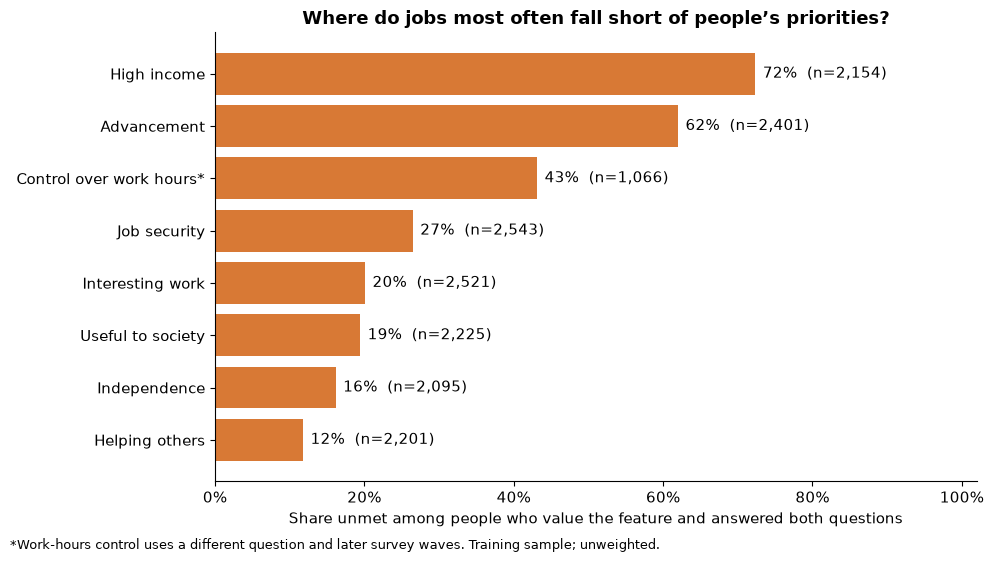

In [4]:
pairs = [
    ('Job security', 'imp_job_security', 'actual_job_secure'),
    ('High income', 'imp_income', 'actual_income_high'),
    ('Advancement', 'imp_advancement', 'actual_advancement_high'),
    ('Interesting work', 'imp_interesting', 'actual_job_interesting'),
    ('Independence', 'imp_independence', 'actual_work_independently'),
    ('Helping others', 'imp_help_others', 'actual_help_others'),
    ('Useful to society', 'imp_useful_society', 'actual_useful_society'),
    ('Control over work hours*', 'imp_decide_hours', 'working_hours_conditions'),
]
assert set(df.filter(regex='^imp_').columns) == {p for _, p, _ in pairs}
priority_cols = [p for _, p, _ in pairs]
offer_cols = [a for _, _, a in pairs]
priorities = df[priority_cols].where(df[priority_cols].isin(range(1, 6)))
offers = df[offer_cols].copy()
for _, _, a in pairs:
    offers[a] = offers[a].where(offers[a].isin([1, 2, 3] if a == 'working_hours_conditions' else range(1, 6)))
unmet = pd.DataFrame(index=df.index)
valid_pairs, is_important, is_provided = {}, {}, {}
for name, p, a in pairs:
    valid = priorities[p].notna() & offers[a].notna()
    important = priorities[p].le(2)
    provided = offers[a].ge(2) if a == 'working_hours_conditions' else offers[a].le(2)
    col = 'unmet_' + p.removeprefix('imp_')
    unmet[col] = (important & ~provided).astype(float).where(valid)
    valid_pairs[name], is_important[name], is_provided[name] = valid, important, provided
assert unmet.stack().dropna().isin([0, 1]).all()
assert all(unmet[c].isna().equals(~valid_pairs[name]) for c, (name, _, _) in zip(unmet, pairs))
core_gap_cols = list(unmet.columns[:7])
# Require all seven observations; never mistake unanswered questions for zero gaps.
core_unmet_count = unmet[core_gap_cols].sum(axis=1, min_count=7)
count_group = core_unmet_count.clip(upper=3)

def wilson(k, n):
    if n == 0: return (np.nan, np.nan)
    z = 1.96
    prop = k / n
    center = (prop + z*z/(2*n)) / (1 + z*z/n)
    half = z*np.sqrt(prop*(1-prop)/n + z*z/(4*n*n)) / (1 + z*z/n)
    return center-half, center+half

def rate_row(mask):
    values = y_binary.loc[mask]
    n, k = len(values), int(values.sum())
    lo, hi = wilson(k, n)
    return {'n': n, 'top_rate': k/n if n else np.nan, 'lower': lo, 'upper': hi}

train_mask = pd.Series(df.index.isin(train_idx), index=df.index)
gap_records, relationship_records = [], []
for name, p, a in pairs:
    eligible = train_mask & valid_pairs[name] & is_important[name]
    met = eligible & is_provided[name]
    missing_priority = eligible & ~is_provided[name]
    met_result, unmet_result = rate_row(met), rate_row(missing_priority)
    gap_records.append({'Preference': name, 'Important + observed (n)': int(eligible.sum()),
                        'Unmet (n)': int(missing_priority.sum()),
                        'Unmet share': missing_priority.sum()/eligible.sum()})
    relationship_records.append({'Preference': name, 'Met n': met_result['n'], 'Unmet n': unmet_result['n'],
        'Met top rate': met_result['top_rate'], 'Unmet top rate': unmet_result['top_rate'],
        'Difference (pp)': 100*(met_result['top_rate']-unmet_result['top_rate']),
        'Met lower': met_result['lower'], 'Met upper': met_result['upper'],
        'Unmet lower': unmet_result['lower'], 'Unmet upper': unmet_result['upper']})
gap_summary = pd.DataFrame(gap_records).sort_values('Unmet share', ascending=False)
relationships = pd.DataFrame(relationship_records)
display(gap_summary.assign(**{'Unmet share': lambda d: (100*d['Unmet share']).round(1)}).rename(columns={'Unmet share': 'Unmet (%)'}))
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.barh(gap_summary.Preference, gap_summary['Unmet share'], color=ORANGE)
ax.invert_yaxis()
for i, row in enumerate(gap_summary.to_dict('records')):
    ax.text(row['Unmet share']+.01, i, f"{row['Unmet share']:.0%}  (n={row['Important + observed (n)']:,})", va='center')
ax.set(xlim=(0, 1.02), xlabel='Share unmet among people who value the feature and answered both questions',
       title='Where do jobs most often fall short of people’s priorities?')
ax.xaxis.set_major_formatter(PercentFormatter(1))
fig.text(.01, -.01, '*Work-hours control uses a different question and later survey waves. Training sample; unweighted.', fontsize=9)
fig.tight_layout()
show_save(fig, '01_unmet_priorities.png')

### A common shortfall is not necessarily the strongest satisfaction relationship

The next graph compares people **who value the same attribute**: those who report receiving it and those who do not affirm receiving it. The outcome is the percentage **completely satisfied**, not the combined top three satisfaction categories. Lines show approximate 95% intervals for each percentage. These are unadjusted associations; other differences between the groups can explain part of them.

In [5]:
# Source and sample sizes for the graph immediately below.
source_description = (
    "Source: International Social Survey Programme (ISSP), Work Orientations I–IV "
    "cumulative dataset, GESIS study ZA8797, version 1.0.0 (1989, 1997, 2005, 2015). "
    "Local file: data/constructed_datasets/issp.csv, constructed from "
    "data/spss_data/ZA8797_v1-0-0.sav. US respondents are selected with country == 840."
)
display(Markdown('### Data source and respondent counts\n\n' + source_description +
    '\n\n[Dataset DOI](https://doi.org/10.4232/1.14391) · '
    '[Official variable report](https://access.gesis.org/dbk/77968)'))
sample_counts = pd.DataFrame([
    ('All countries in the local ISSP file', len(raw)),
    ('US respondents before satisfaction filtering', len(us)),
    ('US respondents excluded: missing or invalid satisfaction', len(us)-len(df)),
    ('US analysis sample with valid satisfaction (scores 1–7)', len(df)),
    ('Training sample used for the graph below', len(train_idx)),
    ('Test sample, excluded from the graph below', len(test_idx)),
], columns=['Sample', 'Respondents (n)'])
assert raw['cumu_id'].notna().all() and raw['cumu_id'].is_unique
display(sample_counts)
source_rows = []
for i, (name, preference, offer) in enumerate(pairs):
    r = relationships.loc[relationships.Preference.eq(name)].iloc[0]
    source_rows.append({
        'Fit gap': name,
        'Dataset': 'ISSP ZA8797',
        'Preference column (original variable)': f'{preference} (v{11+i})',
        'Job-provision column (original variable)': f'{offer} (v{25+i if i<7 else 44})',
        'US valid pairs (analysis sample)': int(valid_pairs[name].sum()),
        'Graph n (training, values feature)': int(r['Met n'] + r['Unmet n']),
        'Met n': int(r['Met n']),
        'Unmet n': int(r['Unmet n']),
    })
fit_gap_sources = pd.DataFrame(source_rows)
assert (fit_gap_sources['Graph n (training, values feature)'] ==
        fit_gap_sources['Met n'] + fit_gap_sources['Unmet n']).all()
display(Markdown('**Columns and sample sizes for each fit gap shown in the graph:**'))
display(fit_gap_sources)
source_note = (
    'All eight gaps in this graph use ISSP responses for both preference and job provision. '
    'The outcome is ISSP job_satisfaction (original v40), with score 1 meaning completely satisfied. '
    'US valid pairs counts respondents with both answers in the full analysis sample; '
    'Graph n additionally restricts to training respondents who value the feature. '
    'The same respondent can appear in several rows, so row counts must not be added together. '
    'Counts are unweighted. *Work-hours control is unavailable in 1989 and uses a different response scale. '
    'O*NET is used in the later, separate autonomy comparison; it supplies none of the eight job-provision columns shown here.'
)
display(Markdown(source_note))
fit_gap_sources.to_csv(OUT/'fit_gap_data_sources.csv',index=False)
sample_counts.to_csv(OUT/'sample_counts.csv',index=False)
source_html = (
    '<section><h2>Data source and respondent counts</h2><p>' + html.escape(source_description) +
    '</p><p><a href="https://doi.org/10.4232/1.14391">Dataset DOI</a> · '
    '<a href="https://access.gesis.org/dbk/77968">Official variable report</a></p>' +
    sample_counts.to_html(index=False) +
    '<h3>Columns used for each fit gap</h3><div class="table">' +
    fit_gap_sources.to_html(index=False) + '</div><p class="note">' + html.escape(source_note) + '</p></section>'
)


### Data source and respondent counts

Source: International Social Survey Programme (ISSP), Work Orientations I–IV cumulative dataset, GESIS study ZA8797, version 1.0.0 (1989, 1997, 2005, 2015). Local file: data/constructed_datasets/issp.csv, constructed from data/spss_data/ZA8797_v1-0-0.sav. US respondents are selected with country == 840.

[Dataset DOI](https://doi.org/10.4232/1.14391) · [Official variable report](https://access.gesis.org/dbk/77968)

,Sample,Respondents (n)
0,All countries in the local ISSP file,122003
1,US respondents before satisfaction filtering,5676
2,US respondents excluded: missing or invalid sa...,2020
3,US analysis sample with valid satisfaction (sc...,3656
4,Training sample used for the graph below,2742
5,"Test sample, excluded from the graph below",914


**Columns and sample sizes for each fit gap shown in the graph:**

,Fit gap,Dataset,Preference column (original variable),Job-provision column (original variable),US valid pairs (analysis sample),"Graph n (training, values feature)",Met n,Unmet n
0,Job security,ISSP ZA8797,imp_job_security (v11),actual_job_secure (v25),3583,2543,1869,674
1,High income,ISSP ZA8797,imp_income (v12),actual_income_high (v26),3582,2154,595,1559
2,Advancement,ISSP ZA8797,imp_advancement (v13),actual_advancement_high (v27),3578,2401,912,1489
3,Interesting work,ISSP ZA8797,imp_interesting (v14),actual_job_interesting (v28),3590,2521,2014,507
4,Independence,ISSP ZA8797,imp_independence (v15),actual_work_independently (v29),3586,2095,1756,339
5,Helping others,ISSP ZA8797,imp_help_others (v16),actual_help_others (v30),3587,2201,1941,260
6,Useful to society,ISSP ZA8797,imp_useful_society (v17),actual_useful_society (v31),3575,2225,1792,433
7,Control over work hours*,ISSP ZA8797,imp_decide_hours (v18),working_hours_conditions (v44),2732,1066,606,460


All eight gaps in this graph use ISSP responses for both preference and job provision. The outcome is ISSP job_satisfaction (original v40), with score 1 meaning completely satisfied. US valid pairs counts respondents with both answers in the full analysis sample; Graph n additionally restricts to training respondents who value the feature. The same respondent can appear in several rows, so row counts must not be added together. Counts are unweighted. *Work-hours control is unavailable in 1989 and uses a different response scale. O*NET is used in the later, separate autonomy comparison; it supplies none of the eight job-provision columns shown here.

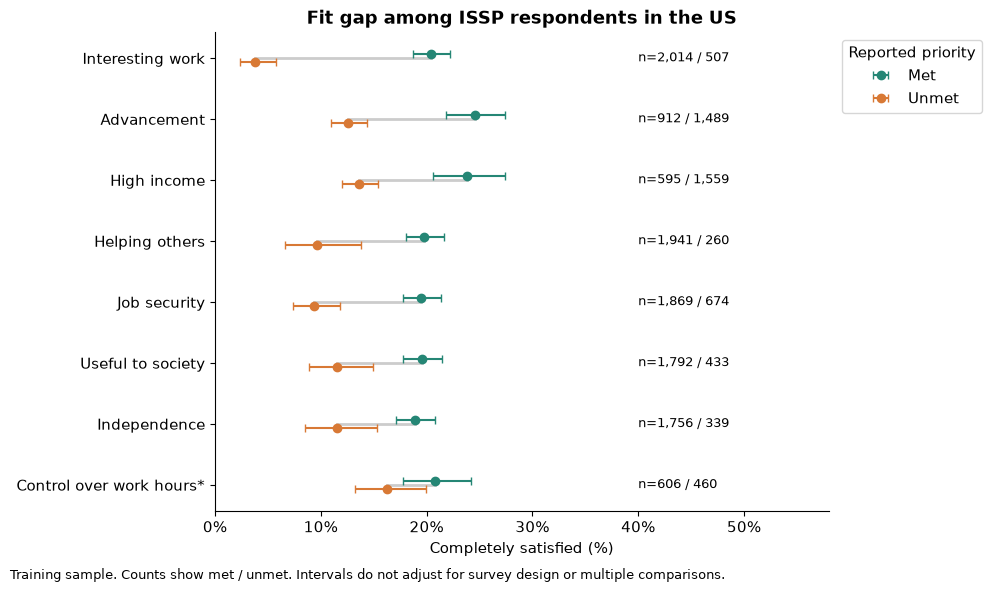

,Preference,Met n,Unmet n,Met top rate,Unmet top rate,Difference (pp)
0,Interesting work,2014,507,0.204,0.037,16.660
1,Advancement,912,1489,0.246,0.126,12.003
2,High income,595,1559,0.239,0.137,10.203
3,Helping others,1941,260,0.198,0.096,10.168
4,Job security,1869,674,0.195,0.093,10.128
5,Useful to society,1792,433,0.196,0.115,8.040
6,Independence,1756,339,0.189,0.115,7.402
7,Control over work hours*,606,460,0.208,0.163,4.488


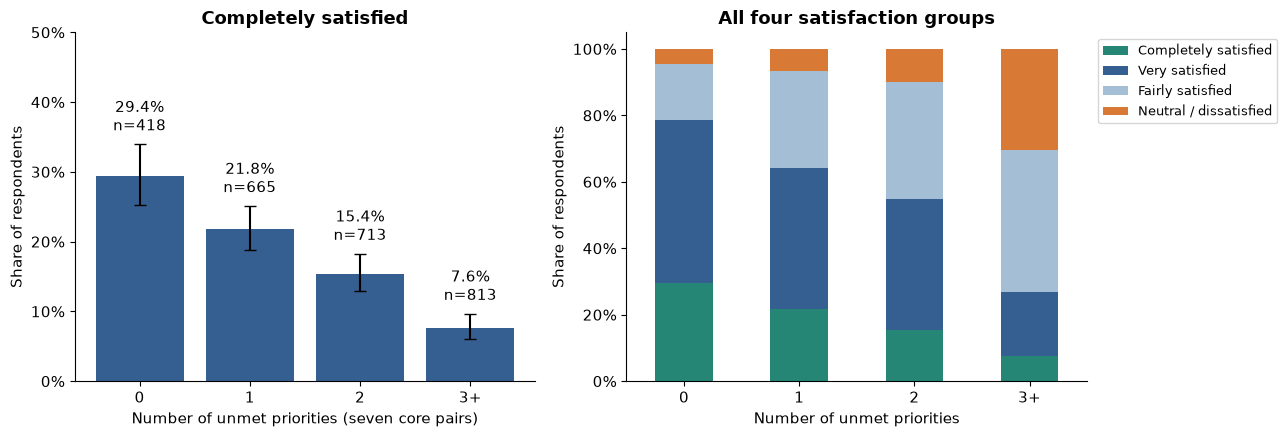

Complete seven-pair training records: 2,609/2,742; incomplete records excluded from this chart only.


,Year,Group,n,top_rate
0,1989,0 unmet,99,0.333
1,1989,3+ unmet,207,0.053
2,1997,0 unmet,79,0.241
3,1997,3+ unmet,209,0.057
4,2005,0 unmet,120,0.300
5,2005,3+ unmet,212,0.132
6,2015,0 unmet,120,0.292
7,2015,3+ unmet,185,0.059


,Definition,n,top_rate,lower,upper
0,Neutral job ratings excluded: 0 unmet,296,0.334,0.283,0.390
1,Neutral job ratings excluded: 3+ unmet,183,0.087,0.055,0.137


In [6]:
ordered = relationships.sort_values('Difference (pp)', ascending=False).reset_index(drop=True)
fig, ax = plt.subplots(figsize=(10, 5.8))
for i, row in ordered.iterrows():
    ax.plot([row['Unmet top rate'], row['Met top rate']], [i, i], color='#cccccc', linewidth=2)
    for group, offset, color in [('Met', -.07, GREEN), ('Unmet', .07, ORANGE)]:
        val = row[group+' top rate']
        ax.errorbar(val, i+offset, xerr=[[val-row[group+' lower']], [row[group+' upper']-val]],
                    fmt='o', color=color, capsize=3, label=group if i == 0 else None)
    ax.text(.40, i, f"n={int(row['Met n']):,} / {int(row['Unmet n']):,}", va='center', fontsize=9)
ax.set_yticks(np.arange(len(ordered)), ordered.Preference)
ax.invert_yaxis()
ax.set(xlim=(0, .58), xlabel='Completely satisfied (%)', title='Fit gap among ISSP respondents in the US')
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.legend(loc='upper left', bbox_to_anchor=(1.01, 1), title='Reported priority')
fig.text(.01, -.01, 'Training sample. Counts show met / unmet. Intervals do not adjust for survey design or multiple comparisons.', fontsize=9)
fig.tight_layout()
show_save(fig, '02_priority_satisfaction.png')
display(ordered[['Preference', 'Met n', 'Unmet n', 'Met top rate', 'Unmet top rate', 'Difference (pp)']].round(3))

count_records=[]
for group in range(4):
    record = rate_row(train_mask & count_group.eq(group))
    count_records.append({'Unmet priorities': str(group) if group<3 else '3+', **record})
count_summary = pd.DataFrame(count_records)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].bar(count_summary['Unmet priorities'], count_summary.top_rate, color=BLUE)
axes[0].errorbar(np.arange(4), count_summary.top_rate,
    yerr=[count_summary.top_rate-count_summary.lower, count_summary.upper-count_summary.top_rate],
    fmt='none', color='black', capsize=4)
for i, row in count_summary.iterrows():
    axes[0].text(i, row['upper']+.02, f"{row.top_rate:.1%}\nn={row.n:,}", ha='center')
axes[0].set(title='Completely satisfied', xlabel='Number of unmet priorities (seven core pairs)', ylabel='Share of respondents', ylim=(0,.5))
axes[0].yaxis.set_major_formatter(PercentFormatter(1))
ct = pd.crosstab(count_group[train_mask], y_four[train_mask]).reindex(index=[0,1,2,3], columns=[1,2,3,4], fill_value=0)
ct = ct.div(ct.sum(axis=1), axis=0)
ct.index=['0','1','2','3+']
ct.columns=['Completely satisfied', 'Very satisfied', 'Fairly satisfied', 'Neutral / dissatisfied']
ct.plot.bar(stacked=True, ax=axes[1], color=[GREEN, BLUE, '#a4bed6', ORANGE], rot=0)
axes[1].set(title='All four satisfaction groups', xlabel='Number of unmet priorities', ylabel='Share of respondents')
axes[1].yaxis.set_major_formatter(PercentFormatter(1))
axes[1].legend(loc='upper left', bbox_to_anchor=(1.01,1), fontsize=9)
fig.tight_layout()
show_save(fig, '03_fit_and_satisfaction.png')
print(f'Complete seven-pair training records: {int(count_summary.n.sum()):,}/{len(train_idx):,}; incomplete records excluded from this chart only.')

# Two descriptive checks fixed in advance: by wave, and exclude neutral job ratings.
wave_rows=[]
for year in sorted(df.module_year.unique()):
    for group, mask in [('0 unmet', core_unmet_count.eq(0)), ('3+ unmet', core_unmet_count.ge(3))]:
        wave_rows.append({'Year': int(year), 'Group': group, **rate_row(train_mask & df.module_year.eq(year) & mask)})
display(pd.DataFrame(wave_rows)[['Year','Group','n','top_rate']].round(3))
strict = pd.DataFrame(index=df.index)
for name,p,a in pairs[:7]:
    known = priorities[p].notna() & offers[a].isin([1,2,4,5])
    strict[p] = (priorities[p].le(2) & offers[a].ge(4)).astype(float).where(known)
strict_count = strict.sum(axis=1, min_count=7)
strict_summary=pd.DataFrame([
    {'Definition': 'Neutral job ratings excluded: 0 unmet', **rate_row(train_mask & strict_count.eq(0))},
    {'Definition': 'Neutral job ratings excluded: 3+ unmet', **rate_row(train_mask & strict_count.ge(3))},
])
display(strict_summary.round(3))

### What does O*NET contribute?

O*NET's Freedom to Make Decisions rates decision freedom for an occupation. Match it through `ONET_SOC_CODE`, excluding suppressed ratings. The job is treated as offering less than “some freedom” when its CX rating is **below 4**. If independence is important and the occupation falls below that threshold, flag an **O*NET autonomy shortfall**. This is an approximate occupation-level comparison, not a report about an individual's workplace.

The threshold is chosen from scale wording, not test performance. The numeric autonomy rating and the shortfall flag both enter the O*NET model variants. O*NET has no matches for the 1989 respondents in this constructed file; coverage is shown by year. No match stays missing. All respondents remain in the prediction experiment.

,n,matched,coverage_percent
year,,,
1989,873,0,0.0
1997,834,537,64.4
2005,1016,654,64.4
2015,933,833,89.3


,Occupation autonomy,n,top_rate,lower,upper
0,Below some freedom,538,0.212,0.179,0.248
1,At least some freedom,613,0.173,0.145,0.205


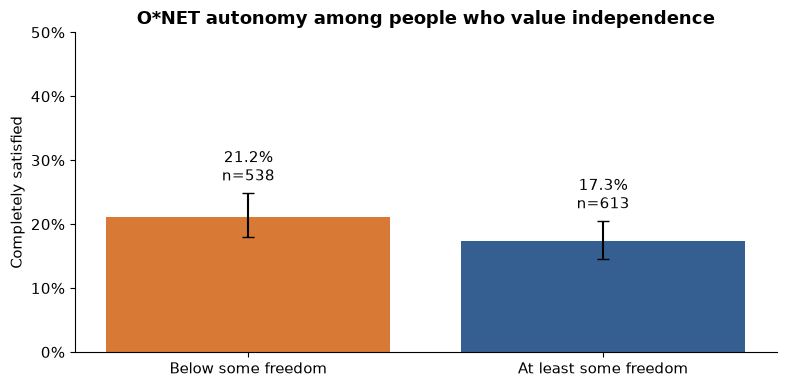

In [7]:
context = pd.read_csv(ROOT / 'data/onet_work_context/freedom_to_make_decisions.csv')
context = context.loc[context['Scale ID'].eq('CX') & context['Element Name'].eq('Freedom to Make Decisions') &
                      context['Recommend Suppress'].fillna('').str.upper().ne('Y')].copy()
context['O*NET-SOC Code'] = context['O*NET-SOC Code'].astype('string').str.strip()
assert context['O*NET-SOC Code'].is_unique and context['Data Value'].between(1,5).all()
autonomy = df['ONET_SOC_CODE'].astype('string').str.strip().map(context.set_index('O*NET-SOC Code')['Data Value'])
onet_gap = (priorities.imp_independence.le(2) & autonomy.lt(4)).astype(float).where(priorities.imp_independence.notna() & autonomy.notna())
onet_features = pd.DataFrame({'onet_autonomy': autonomy, 'onet_autonomy_shortfall': onet_gap})
coverage = pd.DataFrame({'year':df.module_year.astype(int), 'match':autonomy.notna()}).groupby('year').agg(n=('match','size'),matched=('match','sum'))
coverage['coverage_percent'] = (100*coverage.matched/coverage.n).round(1)
display(coverage)
onet_rows=[]
for label, flag in [('Below some freedom', autonomy.lt(4)), ('At least some freedom', autonomy.ge(4))]:
    mask=train_mask & priorities.imp_independence.le(2) & priorities.imp_independence.notna() & autonomy.notna() & flag
    onet_rows.append({'Occupation autonomy':label, **rate_row(mask)})
onet_summary=pd.DataFrame(onet_rows)
display(onet_summary.round(3))
fig, ax=plt.subplots(figsize=(8,4))
ax.bar(onet_summary['Occupation autonomy'], onet_summary.top_rate, color=[ORANGE,BLUE])
ax.errorbar(np.arange(2), onet_summary.top_rate,
    yerr=[onet_summary.top_rate-onet_summary.lower,onet_summary.upper-onet_summary.top_rate],fmt='none',color='black',capsize=4)
for i,row in onet_summary.iterrows(): ax.text(i,row['upper']+.02,f"{row.top_rate:.1%}\nn={row.n:,}",ha='center')
ax.set(title='O*NET autonomy among people who value independence',ylabel='Completely satisfied',ylim=(0,.5))
ax.yaxis.set_major_formatter(PercentFormatter(1))
fig.tight_layout()
show_save(fig,'04_onet_autonomy.png')

### What O*NET actually provides

O*NET describes **occupations, not individual people or workplaces**. We use its **Freedom to Make Decisions** rating, a 1–5 measure of how much decision freedom a job typically offers. We link each ISSP respondent to that occupation rating through `ONET_SOC_CODE`. People with the same matched occupation receive the same rating even if their employers give them different levels of freedom.

For this graph, we keep people who say independence matters to them and compare occupations rated **below 4** versus **4 or above** (“some freedom” or more). This is an approximate occupation-level comparison; it does not directly measure each person's actual autonomy. The eight main fit gaps come from ISSP's own preference and job-provision questions. O*NET supplies an external autonomy rating and shortfall flag, not eight complete fit dimensions.

Adding O*NET showed **no clear additional predictive benefit beyond ISSP fit** in these experiments. Missing occupation matches and later occupation ratings applied to historical respondents limit what we can infer. Source: [O*NET decision-making freedom](https://www.onetonline.org/find/descriptor/result/4.C.3.a.4).


## 2. Train the models on the same respondents

All versions use a decision tree, the same train/test split, and the same training-only search settings. Missing values are imputed inside each training fold. Keep all 3,656 respondents; only charts requiring observed pairs use smaller samples.

| Version | Features added to the original baseline | What it tests |
|---|---|---|
| Baseline | None | Original benchmark |
| ISSP fit | Eight unmet-priority flags | Whether reported fit helps |
| ISSP fit + O*NET | Eight flags + O*NET autonomy and shortfall | Main combined-source fit model |
| Job conditions | Eight reported job conditions | Whether job quality alone explains prediction gains |
| Conditions + priorities | Conditions + eight importance ratings | Whether knowing the person's priorities helps |
| Components + fit | Conditions + priorities + eight unmet flags | Whether engineered fit helps beyond the ratings that define it |
| All features | Components + fit + O*NET | Whether occupation data adds to the richer model |

The explicit gaps contain no new information beyond their source ratings, but may help a shallow tree express interactions. An improvement over baseline alone does not isolate the effect of personal fit.

**Primary binary metric:** average precision, which evaluates ranking of the completely satisfied group. **Four-class metric:** macro F1, giving each class equal weight. Accuracy is also shown. Model settings are chosen using three training folds; test predictions use the default class rule. No test threshold tuning.

This test sample has already been used in earlier notebooks. Treat this comparison as exploratory, not a fresh final validation.

In [8]:
X_all = pd.concat([X, priorities, offers, unmet, onet_features],axis=1)
gap_cols=list(unmet.columns)
onet_cols=list(onet_features.columns)
variants={
    'Baseline': [],
    'ISSP fit': gap_cols,
    'ISSP fit + O*NET': gap_cols + onet_cols,
    'Job conditions': offer_cols,
    'Conditions + priorities': offer_cols + priority_cols,
    'Components + fit': offer_cols + priority_cols + gap_cols,
    'All features': offer_cols + priority_cols + gap_cols + onet_cols,
}
assert X_all.columns.is_unique and len(X_all)==len(df)
assert all(X_all[c].iloc[train_idx].notna().any() for c in X_all)
assert set(X_all).isdisjoint({'job_satisfaction','cumu_id','case_id','ONET_SOC_CODE'})

def build_model(extra):
    preprocessing=ColumnTransformer([
        ('numeric',SimpleImputer(strategy='median'),numeric_features+extra),
        ('categorical',Pipeline([
            ('imputer',SimpleImputer(strategy='most_frequent')),
            ('encoder',OneHotEncoder(handle_unknown='ignore'))]),categorical_features)])
    return Pipeline([('preprocessing',preprocessing),('model',DecisionTreeClassifier(random_state=SEED))])

param_grid={'model__max_depth':[2,3,4,5], 'model__min_samples_leaf':[25,75], 'model__class_weight':[None,'balanced']}
cv=StratifiedKFold(n_splits=3,shuffle=True,random_state=SEED)
models,predictions,probabilities={}, {}, {}
model_rows,cv_rows=[],[]
for task_name,task in tasks.items():
    y_train,y_test=task['y'].iloc[train_idx],task['y'].iloc[test_idx]
    for variant,extra in variants.items():
        columns=features+extra
        search=GridSearchCV(build_model(extra),param_grid,scoring=task['scoring'],cv=cv,n_jobs=1,refit=True)
        search.fit(X_all.iloc[train_idx][columns],y_train)
        model=search.best_estimator_
        pred=model.predict(X_all.iloc[test_idx][columns])
        models[task_name,variant]=model
        predictions[task_name,variant]=pred
        row={'Task':task_name,'Version':variant,
             'Accuracy':accuracy_score(y_test,pred), 'Balanced accuracy':balanced_accuracy_score(y_test,pred),
             'Macro F1':f1_score(y_test,pred,average='macro',zero_division=0)}
        # Class 1 is completely satisfied for both targets; evaluate it versus all other classes.
        pos=list(model.named_steps['model'].classes_).index(1)
        prob=model.predict_proba(X_all.iloc[test_idx][columns])[:,pos]
        probabilities[task_name,variant]=prob
        top_truth=y_test.eq(1)
        top_prediction=(pred == 1)
        row.update({'Average precision':average_precision_score(top_truth,prob),
                    'Top-class precision':precision_score(top_truth,top_prediction,zero_division=0),
                    'Top-class recall':recall_score(top_truth,top_prediction,zero_division=0)})
        model_rows.append(row)
        cv_rows.append({'Task':task_name,'Version':variant,'CV metric':task['scoring'],
                        'CV score':search.best_score_,**{k.removeprefix('model__'):v for k,v in search.best_params_.items()}})
        print(f'{task_name} / {variant}: training CV {task["scoring"]}={search.best_score_:.3f}')
results=pd.DataFrame(model_rows).set_index(['Task','Version'])
cv_results=pd.DataFrame(cv_rows)
print('Training-only model selection:')
display(cv_results.round(3))

Binary / Baseline: training CV average_precision=0.217


Binary / ISSP fit: training CV average_precision=0.250


Binary / ISSP fit + O*NET: training CV average_precision=0.250


Binary / Job conditions: training CV average_precision=0.388


Binary / Conditions + priorities: training CV average_precision=0.389


Binary / Components + fit: training CV average_precision=0.389


... (5 outputs left out)

Four-class / Conditions + priorities: training CV f1_macro=0.460


Four-class / Components + fit: training CV f1_macro=0.465


Four-class / All features: training CV f1_macro=0.465
Training-only model selection:


,Task,Version,CV metric,CV score,class_weight,max_depth,min_samples_leaf
0,Binary,Baseline,average_precision,0.217,balanced,4,25
1,Binary,ISSP fit,average_precision,0.250,balanced,5,75
2,Binary,ISSP fit + O*NET,average_precision,0.250,balanced,5,75
3,Binary,Job conditions,average_precision,0.388,balanced,5,75
4,Binary,Conditions + priorities,average_precision,0.389,balanced,5,75
5,Binary,Components + fit,average_precision,0.389,balanced,5,75
6,Binary,All features,average_precision,0.389,balanced,5,75
7,Four-class,Baseline,f1_macro,0.275,balanced,4,75
8,Four-class,ISSP fit,f1_macro,0.378,balanced,5,25
9,Four-class,ISSP fit + O*NET,f1_macro,0.381,balanced,5,25


## 3. Did fit improve prediction?

All numbers below describe the **same 914 test respondents**. Higher scores are better. A change in accuracy from 30% to 35% is **+5 percentage points**. A higher accuracy does not necessarily mean better recognition of the completely satisfied group, so also examine average precision and class-specific precision/recall.

Read the comparison in this order: baseline → ISSP fit → ISSP fit + O*NET. Then check job conditions and source ratings to see whether the improvement really requires an explicit fit calculation.

For **both binary and four-class models**, Average precision, Top-class precision, and Top-class recall evaluate **score 1 (completely satisfied) versus every other response**. Average precision uses the predicted probability of class 1; precision and recall use whether the final predicted class is 1. Macro F1 and balanced accuracy still summarize all classes.

Accuracy  Balanced accuracy  Macro F1  \
Task       Version                                                          
Binary     Baseline                    0.590              0.572     0.510   
           ISSP fit                    0.609              0.635     0.544   
           ISSP fit + O*NET            0.609              0.635     0.544   
           Job conditions              0.681              0.690     0.604   
           Conditions + priorities     0.681              0.690     0.604   
           Components + fit            0.667              0.693     0.597   
           All features                0.667              0.693     0.597   
Four-class Baseline                    0.264              0.276     0.241   
           ISSP fit                    0.370              0.388     0.373   
           ISSP fit + O*NET            0.370              0.388     0.373   
           Job conditions              0.446              0.461     0.446   
           Conditions + priorities     0.446              0.461     0.446   
           Components + fit            0.446              0.461     0.446   
           All features                0.446              0.461     0.446   

                                    Average precision  Top-class precision  \
Task       Version                                                           
Binary     Baseline                             0.212                0.219   
           ISSP fit                             0.247                0.255   
           ISSP fit + O*NET                     0.255                0.255   
           Job conditions                       0.364                0.309   
           Conditions + priorities              0.364                0.309   
           Components + fit                     0.365                0.303   
           All features                         0.365                0.303   
Four-class Baseline                             0.220                0.235   
           ISSP fit                             0.246                0.233   
           ISSP fit + O*NET                     0.246                0.233   
           Job conditions                       0.349                0.370   
           Conditions + priorities              0.349                0.370   
           Components + fit                     0.349                0.370   
           All features                         0.349                0.370   

                                    Top-class recall  
Task       Version                                    
Binary     Baseline                            0.545  
           ISSP fit                            0.673  
           ISSP fit + O*NET                    0.673  
           Job conditions                      0.705  
           Conditions + priorities             0.705  
           Components + fit                    0.731  
           All features                        0.731  
Four-class Baseline                            0.340  
           ISSP fit                            0.385  
           ISSP fit + O*NET                    0.385  
           Job conditions                      0.494  
           Conditions + priorities             0.494  
           Components + fit                    0.494  
           All features                        0.494

,Task,Comparison,Accuracy change (pp),Primary metric,Metric change
0,Binary,ISSP fit minus Baseline,1.969,Average precision,0.036
1,Binary,ISSP fit + O*NET minus ISSP fit,0.000,Average precision,0.007
2,Binary,ISSP fit + O*NET minus Baseline,1.969,Average precision,0.043
3,Binary,Conditions + priorities minus Job conditions,0.000,Average precision,-0.000
4,Binary,Components + fit minus Conditions + priorities,-1.313,Average precision,0.001
5,Binary,All features minus Components + fit,0.000,Average precision,0.000
6,Four-class,ISSP fit minus Baseline,10.613,Macro F1,0.132
7,Four-class,ISSP fit + O*NET minus ISSP fit,0.000,Macro F1,0.000
8,Four-class,ISSP fit + O*NET minus Baseline,10.613,Macro F1,0.132
9,Four-class,Conditions + priorities minus Job conditions,0.000,Macro F1,0.000


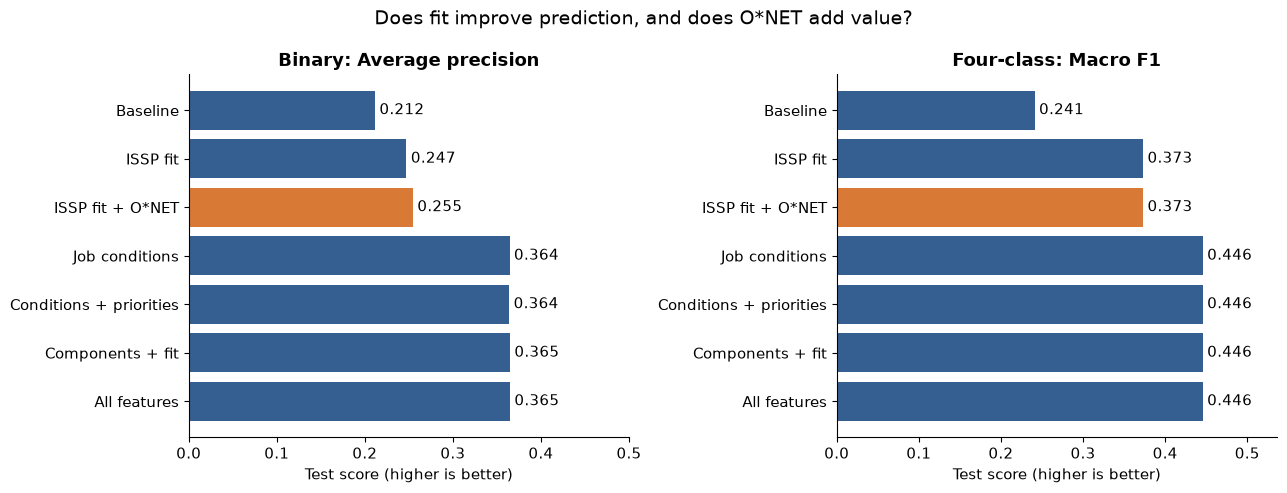


Binary — ISSP fit + O*NET
                          precision    recall  f1-score   support

             Other (2–7)       0.90      0.60      0.72       758
Completely satisfied (1)       0.26      0.67      0.37       156

                accuracy                           0.61       914
               macro avg       0.58      0.63      0.54       914
            weighted avg       0.79      0.61      0.66       914


Four-class — ISSP fit + O*NET
                              precision    recall  f1-score   support

    Completely satisfied (1)       0.23      0.38      0.29       156
          Very satisfied (2)       0.47      0.36      0.40       323
        Fairly satisfied (3)       0.39      0.33      0.36       303
Neutral / dissatisfied (4–7)       0.41      0.48      0.44       132

                    accuracy                           0.37       914
                   macro avg       0.38      0.39      0.37       914
                weighted avg       0.39      0.37  

In [9]:
display(results.round(3))
primary_variant='ISSP fit + O*NET'
comparisons=[('ISSP fit','Baseline'),(primary_variant,'ISSP fit'),(primary_variant,'Baseline'),
             ('Conditions + priorities','Job conditions'),('Components + fit','Conditions + priorities'),
             ('All features','Components + fit')]
delta_rows=[]
for task_name in tasks:
    primary_metric='Average precision' if task_name=='Binary' else 'Macro F1'
    for added,reference in comparisons:
        delta_rows.append({'Task':task_name,'Comparison':f'{added} minus {reference}',
            'Accuracy change (pp)':100*(results.loc[(task_name,added),'Accuracy']-results.loc[(task_name,reference),'Accuracy']),
            'Primary metric':primary_metric,
            'Metric change':results.loc[(task_name,added),primary_metric]-results.loc[(task_name,reference),primary_metric]})
deltas=pd.DataFrame(delta_rows)
display(deltas.round(3))
fig,axes=plt.subplots(1,2,figsize=(13,5))
for ax,task_name,metric in zip(axes,['Binary','Four-class'],['Average precision','Macro F1']):
    values=results.loc[task_name,metric].reindex(list(variants))
    ax.barh(values.index,values.values,color=[ORANGE if v==primary_variant else BLUE for v in values.index])
    ax.invert_yaxis()
    for i,value in enumerate(values):ax.text(value+.005,i,f'{value:.3f}',va='center')
    ax.set(xlim=(0,max(.5,values.max()+.09)),title=f'{task_name}: {metric}',xlabel='Test score (higher is better)')
fig.suptitle('Does fit improve prediction, and does O*NET add value?',fontsize=14)
fig.tight_layout()
show_save(fig,'05_model_comparison.png')
for task_name,task in tasks.items():
    print('\n'+task_name+' — '+primary_variant)
    print(classification_report(task['y'].iloc[test_idx],predictions[task_name,primary_variant],
                                labels=task['labels'],target_names=task['names'],zero_division=0))

### How certain are the differences?

These paired bootstrap intervals resample test respondents 500 times, using the same sampled people for each model in a comparison. Intervals crossing zero do not establish the direction of a difference. They describe uncertainty conditional on the fitted models, not uncertainty from choosing a different training sample. They also do not account for the full survey design or occupation clustering.

Check the combined fit model against baseline, O*NET's contribution beyond ISSP fit, and engineered gaps beyond their underlying ratings. Those answer three different questions.

In [10]:
rng=np.random.default_rng(SEED)
interval_rows=[]
interval_pairs=[(primary_variant,'Baseline'),(primary_variant,'ISSP fit'),('Components + fit','Conditions + priorities')]
for task_name,task in tasks.items():
    truth=task['y'].iloc[test_idx].to_numpy()
    primary_metric='Average precision' if task_name=='Binary' else 'Macro F1'
    for added,reference in interval_pairs:
        draws,accuracy_draws=[],[]
        for _ in range(500):
            sample=rng.integers(0,len(truth),len(truth))
            yt=truth[sample]
            pa=predictions[task_name,added][sample]
            pr=predictions[task_name,reference][sample]
            accuracy_draws.append(np.mean(pa==yt)-np.mean(pr==yt))
            if task_name=='Binary':
                difference=average_precision_score(yt,probabilities[task_name,added][sample])-average_precision_score(yt,probabilities[task_name,reference][sample])
            else:
                difference=f1_score(yt,pa,labels=task['labels'],average='macro',zero_division=0)-f1_score(yt,pr,labels=task['labels'],average='macro',zero_division=0)
            draws.append(difference)
        lo,hi=np.quantile(draws,[.025,.975])
        alo,ahi=np.quantile(accuracy_draws,[.025,.975])*100
        interval_rows.append({'Task':task_name,'Comparison':f'{added} minus {reference}','Metric':primary_metric,
            'Change':results.loc[(task_name,added),primary_metric]-results.loc[(task_name,reference),primary_metric],
            '95% lower':lo,'95% upper':hi,'Accuracy lower (pp)':alo,'Accuracy upper (pp)':ahi})
intervals=pd.DataFrame(interval_rows)
display(intervals.round(3))

# A fixed descriptive check on the test sample; do not change definitions based on its result.
test_mask=~train_mask
test_count_summary=pd.DataFrame([{'Unmet priorities':str(g) if g<3 else '3+',**rate_row(test_mask & count_group.eq(g))} for g in range(4)])
print('Does the seven-priority relationship appear in the test sample as well?')
display(test_count_summary[['Unmet priorities','n','top_rate']].round(3))

,Task,Comparison,Metric,Change,95% lower,95% upper,Accuracy lower (pp),Accuracy upper (pp)
0,Binary,ISSP fit + O*NET minus Baseline,Average precision,0.043,0.004,0.084,-1.641,6.018
1,Binary,ISSP fit + O*NET minus ISSP fit,Average precision,0.007,-0.004,0.025,0.000,0.000
2,Binary,Components + fit minus Conditions + priorities,Average precision,0.001,-0.007,0.009,-3.063,0.438
3,Four-class,ISSP fit + O*NET minus Baseline,Macro F1,0.132,0.095,0.167,6.617,14.223
4,Four-class,ISSP fit + O*NET minus ISSP fit,Macro F1,0.000,0.000,0.000,0.000,0.000
5,Four-class,Components + fit minus Conditions + priorities,Macro F1,0.000,0.000,0.000,0.000,0.000


Does the seven-priority relationship appear in the test sample as well?


,Unmet priorities,n,top_rate
0,0,146,0.288
1,1,221,0.258
2,2,248,0.153
3,3+,270,0.059


### How to present this responsibly

- A **frequent shortfall** and a **large satisfaction difference** are different findings. Show both instead of treating the largest gap as the biggest causal driver.
- Self-reported job conditions and satisfaction come from the same survey. Their association can partly reflect overall positive/negative perceptions. These predictors are suitable for understanding current workers; they would be unavailable when predicting satisfaction for a job someone has not taken.
- O*NET averages over occupations and uses later ratings for historical survey respondents. Crosswalk errors, incomplete matches, and differences between workplaces limit its precision. Treat its contribution as an empirical question.
- This analysis is unweighted and descriptive. Age, survey wave, job type, and other factors may explain associations. Demographic controls are not intervention recommendations.
- The test set was reused across earlier exploratory notebooks. A future validation should use a fresh wave or sample; generalization to new occupations requires an occupation-grouped split.
- We can describe differences between satisfaction groups. We cannot claim to have observed people moving from one category to another, or that changing a feature would cause that move.

**Proposed business next step:** use the common shortfalls and strongest observed relationships to choose topics for employee interviews or a prospective workplace study. A meaningful null finding is also useful: if O*NET or engineered gaps add little, say so.

Sources: [ISSP cumulative variable report, ZA8797](https://access.gesis.org/dbk/77968) (preferences v11–v18, job attributes v25–v31, work hours v44, satisfaction v40); [O*NET Freedom to Make Decisions](https://www.onetonline.org/find/descriptor/result/4.C.3.a.4); local O*NET provenance in `data/onet_work_context/README.md`.

In [ ]:
# Presentation interpretation: summarize the current results without retraining.
main_binary = results.loc[('Binary', 'ISSP fit + O*NET')]
main_four = results.loc[('Four-class', 'ISSP fit + O*NET')]
best_four_accuracy = results.loc['Four-class', 'Accuracy'].max()
onet_explanation_html = '<h3>What O*NET actually provides</h3><p>O*NET describes <strong>occupations, not individual people or workplaces</strong>. We use Freedom to Make Decisions: a 1–5 rating of the freedom a job typically offers. Each ISSP respondent is linked through their occupation code. People in the same matched occupation receive the same rating, even if their workplaces differ.</p><p>This graph includes people who value independence. It compares occupations rated below 4 with those rated 4 or above (some freedom or more). It is an approximate occupation-level comparison, not a measurement of each person\'s actual autonomy. The eight main fit gaps use ISSP responses for both preference and job provision; O*NET adds an external autonomy rating and shortfall flag.</p><p>O*NET showed <strong>no clear additional predictive benefit beyond ISSP fit</strong> in these experiments. Incomplete matches and later ratings for historical respondents limit this comparison. <a href="https://www.onetonline.org/find/descriptor/result/4.C.3.a.4">O*NET source and scale</a>.</p>'
takeaways = [
    ('Prediction is still limited', f"The combined fit model correctly predicts {main_four['Accuracy']:.1%} of four-class outcomes. In the binary model, only {main_binary['Top-class precision']:.1%} of people flagged as completely satisfied actually are. The models are not yet dependable for individual recommendations."),
    ('Fit reveals a relationship', 'People with fewer unmet priorities are more often completely satisfied. However, reported job conditions predict better than fit flags, and engineered gaps and O*NET show no clear additional benefit beyond the underlying survey ratings. These are associations, not causal effects.'),
    ('Several factors make prediction difficult', 'Similar satisfaction categories, fewer examples per class, missing workplace information, and simplified yes/no fit measures may limit performance. The four-class split is one plausible reason, not a proven explanation.'),
]
interpretation_md = '## What we can conclude\n\n' + '\n\n'.join('- **' + title + '.** ' + text for title, text in takeaways)
conclusion_html = '<section><h2>What we can conclude</h2><ul>' + ''.join('<li><strong>' + html.escape(title) + '.</strong> ' + html.escape(text) + '</li>' for title, text in takeaways) + '</ul></section>'
display(Markdown(interpretation_md))


## What we can conclude

- **Prediction is still limited.** The combined fit model correctly predicts 37.0% of four-class outcomes. In the binary model, only 25.5% of people flagged as completely satisfied actually are. The models are not yet dependable for individual recommendations.

- **Fit reveals a relationship.** People with fewer unmet priorities are more often completely satisfied. However, reported job conditions predict better than fit flags, and engineered gaps and O*NET show no clear additional benefit beyond the underlying survey ratings. These are associations, not causal effects.

- **Several factors make prediction difficult.** Similar satisfaction categories, fewer examples per class, missing workplace information, and simplified yes/no fit measures may limit performance. The four-class split is one plausible reason, not a proven explanation.

## Possible next steps

- **Manually weighted fit-gap score.** Create a transparent, rule-based score using only fit gaps, with manually chosen weights that give more severe shortfalls greater influence, without learning the weights from training data.

- **Keras neural network.** A neural network built with Keras could learn nonlinear relationships between preferences, job characteristics, and fit gaps, while a softmax output estimates probabilities for each of the four satisfaction classes. This may help capture combinations of features that simpler rules miss, although having more classes alone does not guarantee better performance. With only 3,656 respondents, we would need regularization, early stopping, and comparison against random forest using the same evaluation design to check overfitting.

[Keras structured-data examples](https://keras.io/examples/structured_data/) · [Keras regularization](https://keras.io/api/layers/regularizers/)


In [11]:
next_steps_md = '## Possible next steps\n\n- **Manually weighted fit-gap score.** Create a transparent, rule-based score using only fit gaps, with manually chosen weights that give more severe shortfalls greater influence, without learning the weights from training data.\n\n- **Keras neural network.** A neural network built with Keras could learn nonlinear relationships between preferences, job characteristics, and fit gaps, while a softmax output estimates probabilities for each of the four satisfaction classes. This may help capture combinations of features that simpler rules miss, although having more classes alone does not guarantee better performance. With only 3,656 respondents, we would need regularization, early stopping, and comparison against random forest using the same evaluation design to check overfitting.\n\n[Keras structured-data examples](https://keras.io/examples/structured_data/) · [Keras regularization](https://keras.io/api/layers/regularizers/)\n'
next_steps_html = '<section><h2>Possible next steps</h2><ul><li><strong>Manually weighted fit-gap score.</strong> Create a transparent, rule-based score using only fit gaps, with manually chosen weights that give more severe shortfalls greater influence, without learning the weights from training data.</li><li><strong>Keras neural network.</strong> A neural network built with Keras could learn nonlinear relationships between preferences, job characteristics, and fit gaps, while a softmax output estimates probabilities for each of the four satisfaction classes. This may help capture combinations of features that simpler rules miss, although having more classes alone does not guarantee better performance. With only 3,656 respondents, we would need regularization, early stopping, and comparison against random forest using the same evaluation design to check overfitting.</li></ul><p class="note"><a href="https://keras.io/examples/structured_data/">Keras structured-data examples</a> · <a href="https://keras.io/api/layers/regularizers/">Keras regularization</a></p></section>'
# Save presentation notes without a separate run-findings section.
notes = '# Presentation notes: job fit and complete satisfaction\n\n'
notes += '## Data provenance and sample sizes\n\n' + source_description + '\n\n'
notes += '\n'.join('- ' + str(row['Sample']) + ': ' + format(row['Respondents (n)'], ',')
                   for row in sample_counts.to_dict('records'))
notes += '\n\n' + "### What O*NET actually provides\n\nO*NET describes **occupations, not individual people or workplaces**. We use its **Freedom to Make Decisions** rating, a 1–5 measure of how much decision freedom a job typically offers. We link each ISSP respondent to that occupation rating through `ONET_SOC_CODE`. People with the same matched occupation receive the same rating even if their employers give them different levels of freedom.\n\nFor this graph, we keep people who say independence matters to them and compare occupations rated **below 4** versus **4 or above** (“some freedom” or more). This is an approximate occupation-level comparison; it does not directly measure each person's actual autonomy. The eight main fit gaps come from ISSP's own preference and job-provision questions. O*NET supplies an external autonomy rating and shortfall flag, not eight complete fit dimensions.\n\nAdding O*NET showed **no clear additional predictive benefit beyond ISSP fit** in these experiments. Missing occupation matches and later occupation ratings applied to historical respondents limit what we can infer. Source: [O*NET decision-making freedom](https://www.onetonline.org/find/descriptor/result/4.C.3.a.4).\n" + '\n\n' + interpretation_md + '\n'
notes_path = ROOT / 'notebooks/fit_models/decision_tree/us_job_fit_presentation_notes.md'
notes += '\n\n' + next_steps_md
notes_path.write_text(notes)
results.to_csv(OUT/'model_results.csv')
intervals.to_csv(OUT/'comparison_intervals.csv',index=False)
gap_summary.to_csv(OUT/'unmet_priorities.csv',index=False)
# Save exact membership for subsequent comparisons without exporting predictor responses.
pd.DataFrame({'cumu_id':df.cumu_id,'split':np.where(train_mask,'train','test')}).to_csv(OUT/'respondent_split.csv',index=False)

figures=[('01_unmet_priorities.png','1. Where jobs fall short','Training respondents who value each attribute and answered both questions. Work-hours control uses a different question and later waves.'),
         ('02_priority_satisfaction.png','2. Fit gap among ISSP respondents in the US','Compare respondents who value the same feature. These are unadjusted differences, not causal effects.'),
         ('03_fit_and_satisfaction.png','3. More unmet priorities, different satisfaction profiles','Seven core ISSP pairs; complete observations only. Category 1 remains separate from categories 2 and 3.'),
         ('04_onet_autonomy.png','4. An independent occupation perspective','O*NET autonomy among respondents who value independence; occupation averages may miss differences between workplaces.'),
         ('05_model_comparison.png','5. Does fit improve prediction?','Same 914 test respondents; settings selected using training data only. Orange is the combined ISSP fit + O*NET model.')]
parts=['<!doctype html><html lang="en"><meta charset="utf-8"><meta name="viewport" content="width=device-width, initial-scale=1"><title>Job fit and complete satisfaction</title>',
       '<style>body{font:18px/1.55 system-ui,sans-serif;color:#213248;background:#f3f5f7;margin:0}main{max-width:1120px;margin:auto;padding:40px 24px}section{background:white;padding:28px;margin:26px 0;border-radius:12px}h1{font-size:40px;line-height:1.15}h2{font-size:26px}img{width:100%;height:auto}table{font-size:13px;border-collapse:collapse;width:100%}td,th{padding:8px;border-bottom:1px solid #ddd;text-align:left}.table{overflow:auto}.note{color:#536579;font-size:15px}@media print{section{break-inside:avoid}body{background:white}main{padding:0}h1{font-size:30px}}</style><main>',
       '<h1>What distinguishes completely satisfied workers?</h1><p>US ISSP priorities and reported job conditions, with O*NET occupation autonomy.</p>',
       '<section><h2>What we tested</h2><p>Primary target: completely satisfied (score 1) versus everyone else. Secondary target: scores 1, 2, 3, and 4–7 separately. We studied eight unmet priorities and used the original decision-tree train/test split.</p><p class="note">An unmet priority means the person values an attribute but does not affirm that their job provides it. Only autonomy is matched to O*NET; the other job conditions come from ISSP.</p></section>']
for filename,title,caption in figures:
    if filename == '02_priority_satisfaction.png':
        parts.append(source_html)
    data=base64.b64encode((OUT/filename).read_bytes()).decode('ascii')
    parts.append(f'<section><h2>{html.escape(title)}</h2><img alt="{html.escape(title)}" src="data:image/png;base64,{data}"><p class="note">{html.escape(caption)}</p></section>')
    if filename == '04_onet_autonomy.png':
        parts.append('<section>' + onet_explanation_html + '</section>')
parts.append('<section><h2>Test results</h2><div class="table">'+results.round(3).to_html()+'</div><p class="note">For both tasks, average precision ranks completely satisfied respondents (score 1) versus all others. Top-class precision and recall evaluate predictions of score 1. Macro F1 gives each class equal weight.</p></section>')
parts.append(conclusion_html + next_steps_html + '</main></html>')
html_path=ROOT/'notebooks/fit_models/decision_tree/us_job_fit_presentation.html'
html_path.write_text(''.join(parts))
print('Saved:',html_path,'\n',notes_path,'\nCharts and tables:',OUT)
